# Phân tích hồ sơ phê duyệt tín dụng
Đề tài 3 - Thực hành Trực quan hóa dữ liệu.

Notebook dùng dữ liệu CSV thật do nhóm tải từ nguồn được chỉ định. Mỗi bước có mã và kết quả chạy. Tập trung phân tích mô tả, không dự báo vỡ nợ.

**Chạy trên Colab:** tải notebook lên, sau đó tải `loan_approval_dataset.csv` khi được hỏi ở ô 2. Trên máy cá nhân, chạy từ thư mục `source`.

## 1. Nhập thư viện

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams["font.family"] = "DejaVu Sans"

## 2. Đọc file dữ liệu
Ưu tiên file trong thư mục data hoặc thư mục hiện tại. Nếu chạy Colab và chưa có file, chọn tải file từ máy.

In [2]:
paths = [Path("data/loan_approval_dataset.csv"), Path("loan_approval_dataset.csv")]
path = next((p for p in paths if p.exists()), None)
if path is None:
    from google.colab import files
    uploaded = files.upload()
    path = Path(next(iter(uploaded)))
df_raw = pd.read_csv(path)
df = df_raw.copy()
print("Kích thước:", df.shape)
display(df.head())

Kích thước: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## 3. Chuẩn hóa khoảng trắng
Giữ dữ liệu gốc ở df_raw. Không sửa file đầu vào.

In [3]:
df.columns = df.columns.str.strip()
for col in df.select_dtypes("object"):
    df[col] = df[col].str.strip()
display(pd.DataFrame({"Kiểu dữ liệu": df.dtypes.astype(str), "Số giá trị khác nhau": df.nunique()}))

,Kiểu dữ liệu,Số giá trị khác nhau
loan_id,int64,4269
no_of_dependents,int64,6
education,object,2
self_employed,object,2
income_annum,int64,98
loan_amount,int64,378
loan_term,int64,10
cibil_score,int64,601
residential_assets_value,int64,278
commercial_assets_value,int64,188


## 4. Kiểm tra thiếu, trùng và giá trị bất thường

In [4]:
assets = ["residential_assets_value", "commercial_assets_value", "luxury_assets_value", "bank_asset_value"]
display(df.isna().sum().rename("Giá trị thiếu").to_frame())
print("Dòng trùng:", df.duplicated().sum())
print("Trùng mã:", df.loan_id.duplicated().sum())
print("CIBIL ngoài 300–900:", (~df.cibil_score.between(300,900)).sum())
print("Thu nhập/khoản vay/kỳ hạn không dương:", df[["income_annum","loan_amount","loan_term"]].le(0).any(axis=1).sum())
print("Tài sản âm:", df[assets].lt(0).sum().to_dict())

Dòng trùng: 0
Trùng mã: 0
CIBIL ngoài 300–900: 0
Thu nhập/khoản vay/kỳ hạn không dương: 0
Tài sản âm: {'residential_assets_value': 28, 'commercial_assets_value': 0, 'luxury_assets_value': 0, 'bank_asset_value': 0}


,Giá trị thiếu
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


## 5. Xử lý tài sản âm có dấu vết
28 giá trị tài sản nhà ở âm chưa có thông tin giải thích. Đánh dấu và đổi thành thiếu ở bản phân tích, giữ giá trị gốc. Tổng tài sản chỉ tính khi đủ bốn thành phần. Không bỏ hồ sơ và không tự điền 0.

In [5]:
df["asset_issue"] = df[assets].lt(0).any(axis=1)
df["residential_assets_value_raw"] = df.residential_assets_value
df[assets] = df[assets].mask(df[assets].lt(0))
df["total_assets"] = df[assets].sum(axis=1, min_count=4)
print("Giữ lại", len(df), "hồ sơ")
display(df.loc[df.asset_issue, ["loan_id", "residential_assets_value_raw", "residential_assets_value", "total_assets"]].head(10))

Giữ lại 4269 hồ sơ


,loan_id,residential_assets_value_raw,residential_assets_value,total_assets
59,60,-100000,NaN,NaN
196,197,-100000,NaN,NaN
559,560,-100000,NaN,NaN
702,703,-100000,NaN,NaN
737,738,-100000,NaN,NaN
784,785,-100000,NaN,NaN
904,905,-100000,NaN,NaN
1089,1090,-100000,NaN,NaN
1163,1164,-100000,NaN,NaN
1350,1351,-100000,NaN,NaN


## 6. Biến phân tích và KPI
Khoản vay/thu nhập năm là số lần, không phải DTI. Các nhóm CIBIL là khoảng khám phá, chưa phải xếp hạng chính thức. Không gán đơn vị tiền hoặc tháng/năm khi chưa xác minh.

In [6]:
df["approved"] = df.loan_status.eq("Approved").astype(int)
df["cibil_band"] = pd.cut(df.cibil_score, [299,549,649,749,900], labels=["300–549","550–649","650–749","750–900"])
df["income_group"] = pd.qcut(df.income_annum, 4, labels=["Q1","Q2","Q3","Q4"])
df["loan_income_ratio"] = df.loan_amount / df.income_annum
kpi = pd.Series({"Tổng hồ sơ":len(df), "Được duyệt":int(df.approved.sum()), "Từ chối":int((1-df.approved).sum()), "Tỷ lệ duyệt (%)":100*df.approved.mean(), "Tiền đề nghị vay (đơn vị gốc)":df.loan_amount.sum()})
display(kpi.to_frame("Giá trị"))

,Giá trị
Tổng hồ sơ,4.269000e+03
Được duyệt,2.656000e+03
Từ chối,1.613000e+03
Tỷ lệ duyệt (%),6.221598e+01
Tiền đề nghị vay (đơn vị gốc),6.460470e+10


## 7. Tổng quan và tỷ lệ duyệt theo CIBIL
Luôn xem đồng thời số hồ sơ và tỷ lệ để tránh diễn giải quá mức các nhóm ít quan sát.

,Số hồ sơ,Được duyệt,Tỷ lệ duyệt
cibil_band,,,
300–549,1785,185,0.103641
550–649,683,681,0.997072
650–749,745,740,0.993289
750–900,1056,1050,0.994318


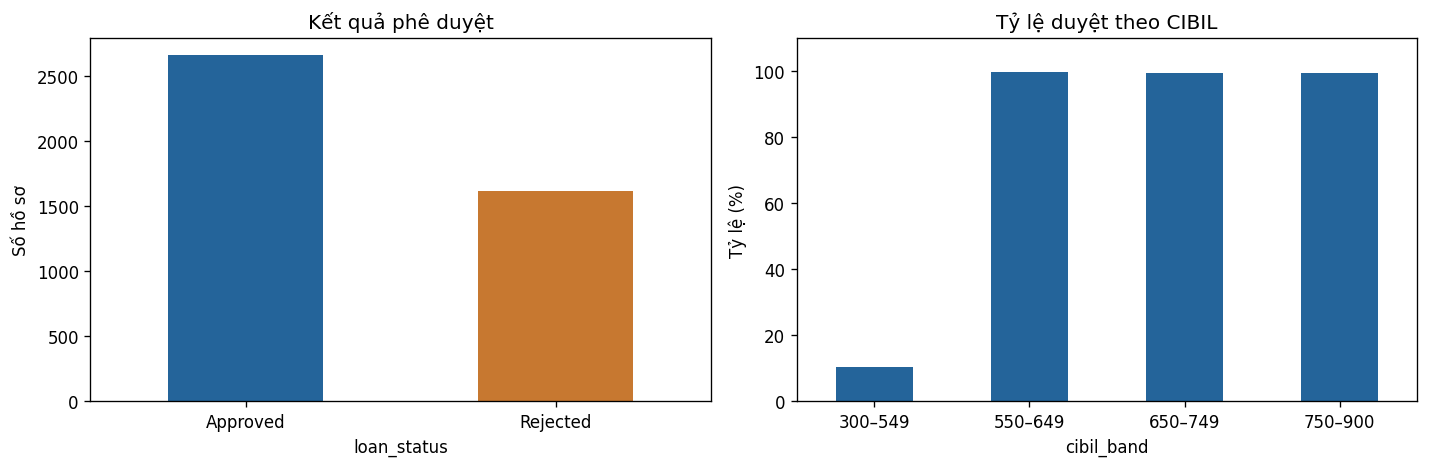

In [7]:
g=df.groupby("cibil_band",observed=True).approved.agg(["size","sum","mean"])
g.columns=["Số hồ sơ","Được duyệt","Tỷ lệ duyệt"]
display(g)
fig, axes=plt.subplots(1,2,figsize=(12,4))
df.loan_status.value_counts().plot.bar(ax=axes[0],color=["#24649a","#c77830"],rot=0)
axes[0].set(title="Kết quả phê duyệt",ylabel="Số hồ sơ")
(g["Tỷ lệ duyệt"]*100).plot.bar(ax=axes[1],color="#24649a",rot=0)
axes[1].set(title="Tỷ lệ duyệt theo CIBIL",ylabel="Tỷ lệ (%)",ylim=(0,110))
plt.tight_layout(); plt.show()

## 8. Phân tích chéo CIBIL và kỳ hạn
Màu biểu diễn tỷ lệ duyệt. Số lượng là mẫu số của từng ô. Kỳ hạn giữ nguyên đơn vị nguồn.

loan_term,2,4,6,8,10,12,14,16,18,20
cibil_band,,,,,,,,,,
300–549,47.65,56.83,0.00,0.0,0.00,0.0,0.00,0.00,0.00,0.00
550–649,100.00,100.00,100.00,100.0,96.72,100.0,100.00,100.00,100.00,100.00
650–749,100.00,100.00,97.73,100.0,100.00,100.0,98.55,100.00,98.67,98.48
750–900,100.00,98.32,99.14,100.0,98.99,100.0,99.05,99.02,100.00,100.00


loan_term,2,4,6,8,10,12,14,16,18,20
cibil_band,,,,,,,,,,
300–549,170,183,205,166,204,180,164,175,164,174
550–649,58,72,81,59,61,68,67,70,72,75
650–749,84,73,88,67,72,86,69,65,75,66
750–900,92,119,116,94,99,122,105,102,111,96


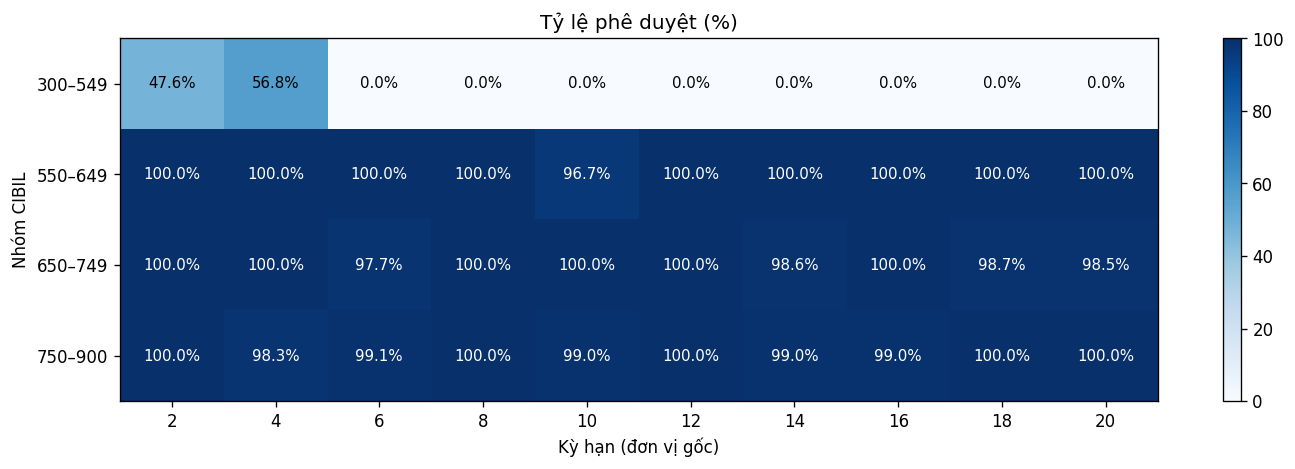

In [8]:
cross=df.groupby(["cibil_band","loan_term"],observed=True).approved.agg(["mean","size"])
rate=cross["mean"].unstack()*100
count=cross["size"].unstack()
display(rate.round(2))
display(count)
fig,ax=plt.subplots(figsize=(12,4))
im=ax.imshow(rate,cmap="Blues",vmin=0,vmax=100,aspect="auto")
ax.set_xticks(range(len(rate.columns)),rate.columns)
ax.set_yticks(range(len(rate.index)),rate.index)
for i in range(len(rate)):
    for j in range(len(rate.columns)):
        v=rate.iloc[i,j]
        ax.text(j,i,f"{v:.1f}%",ha="center",va="center",color="white" if v>60 else "black",fontsize=9)
ax.set(xlabel="Kỳ hạn (đơn vị gốc)",ylabel="Nhóm CIBIL",title="Tỷ lệ phê duyệt (%)")
fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## 9. Thu nhập và tương quan
Mã hồ sơ bị loại khỏi ma trận. Approved mã hóa 1 và Rejected mã hóa 0. Tương quan là mối liên hệ trong mẫu, chưa chứng minh nguyên nhân.

,income_annum,loan_amount,loan_term,cibil_score,loan_income_ratio,approved
income_annum,1.000,0.927,0.011,-0.023,0.020,-0.015
loan_amount,0.927,1.000,0.008,-0.017,0.341,0.016
loan_term,0.011,0.008,1.000,0.008,-0.003,-0.113
cibil_score,-0.023,-0.017,0.008,1.000,0.003,0.771
loan_income_ratio,0.020,0.341,-0.003,0.003,1.000,0.088
approved,-0.015,0.016,-0.113,0.771,0.088,1.000


,size,mean
income_group,,
Q1,1112,0.644784
Q2,1059,0.603399
Q3,1051,0.619410
Q4,1047,0.619866


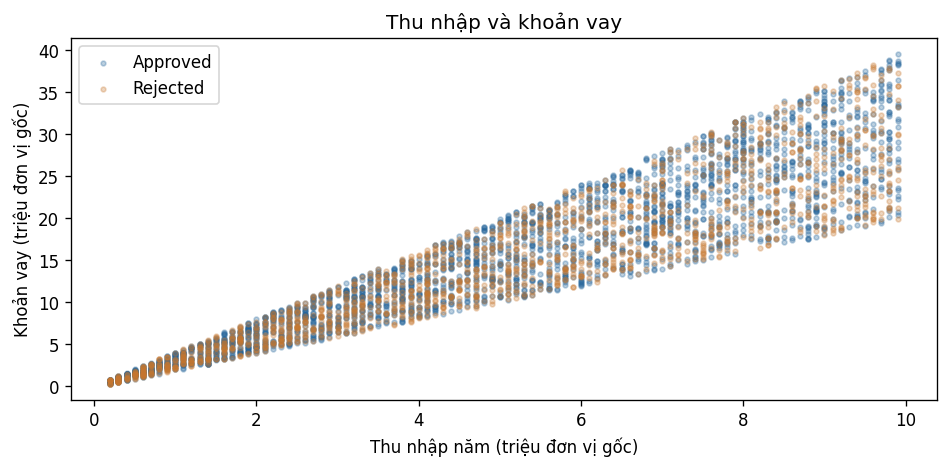

In [9]:
cols=["income_annum","loan_amount","loan_term","cibil_score","loan_income_ratio","approved"]
display(df[cols].corr().round(3))
display(df.groupby("income_group",observed=True).approved.agg(["size","mean"]))
fig,ax=plt.subplots(figsize=(8,4))
for status,color in [("Approved","#24649a"),("Rejected","#c77830")]:
    sub=df.loc[df.loan_status.eq(status)]
    ax.scatter(sub.income_annum/1e6,sub.loan_amount/1e6,s=8,alpha=.3,label=status,color=color)
ax.set(xlabel="Thu nhập năm (triệu đơn vị gốc)",ylabel="Khoản vay (triệu đơn vị gốc)",title="Thu nhập và khoản vay")
ax.legend(); plt.tight_layout(); plt.show()

## 10. Tra cứu ngoại lệ
Ngưỡng 550 là quy ước phân tích. Không dùng ngưỡng này để tự động quyết định cho vay.

In [10]:
threshold=550
low=df.loc[df.cibil_score.lt(threshold) & df.approved.eq(1)]
high=df.loc[df.cibil_score.ge(threshold) & df.approved.eq(0)]
print("Dưới 550 được duyệt:",len(low))
print("Từ 550 bị từ chối:",len(high))
display(low.groupby("loan_term").size().rename("Số hồ sơ"))
display(high[["loan_id","cibil_score","loan_term","income_annum","loan_amount","loan_income_ratio"]])

Dưới 550 được duyệt: 185
Từ 550 bị từ chối: 13


,Số hồ sơ
loan_term,
2,81
4,104


,loan_id,cibil_score,loan_term,income_annum,loan_amount,loan_income_ratio
67,68,693,20,2700000,10100000,3.740741
236,237,770,4,900000,3500000,3.888889
348,349,666,6,2000000,7000000,3.500000
395,396,584,10,800000,3200000,4.000000
559,560,885,6,200000,500000,2.500000
911,912,835,4,1300000,4800000,3.692308
1446,1447,747,18,300000,1200000,4.000000
1950,1951,587,10,200000,700000,3.500000
2856,2857,674,6,8300000,31400000,3.783133
3180,3181,683,14,3200000,12200000,3.812500


## 11. Đối chiếu và xuất dữ liệu
Các kiểm tra này áp dụng đúng phiên bản file 4.269 hồ sơ đã gửi. Nếu thay nguồn, cần cập nhật mốc kiểm tra sau khi đối chiếu.

In [11]:
assert len(df)==4269 and df.approved.sum()==2656
assert df.asset_issue.sum()==28 and df.total_assets.isna().sum()==28
assert len(low)==185 and len(high)==13
assert df.loan_amount.sum()==64604700000
Path("results").mkdir(exist_ok=True)
df.to_csv("results/loan_clean_notebook.csv",index=False,encoding="utf-8-sig")
print("Đã kiểm tra và xuất results/loan_clean_notebook.csv")

Đã kiểm tra và xuất results/loan_clean_notebook.csv


## 12. Kết luận và hướng hành động
- Tỷ lệ duyệt chung 62,22%. Nhóm CIBIL 300–549 đạt 10,36%, các nhóm còn lại trên 99% trong mẫu.
- Toàn bộ 185 hồ sơ dưới 550 được duyệt thuộc kỳ hạn gốc 2 hoặc 4. Cần kiểm tra chéo thay vì chỉ nhìn tổng thể.
- Thu nhập và khoản vay tương quan khoảng 0,928. Thu nhập riêng lẻ gần như không có tương quan tuyến tính với trạng thái duyệt.
- Rà soát 13 hồ sơ CIBIL từ 550 bị từ chối và đối chiếu 28 giá trị tài sản âm.
- Thu thập thêm ngày hồ sơ, mô tả đơn vị và kết quả trả nợ trước khi mở rộng sang giám sát thời gian hoặc rủi ro vỡ nợ.

**Học để vấn đáp:** giải thích mẫu số tỷ lệ, cách xử lý tài sản âm, sự khác biệt tương quan/nhân quả và lý do không tạo dữ liệu thời gian giả.